# UniAug vs. ModeAug

Alanine, 13 atoms, real RHF/6-31G* geometry + Hessian.

$$\Delta E = -\mathbf{F}^{\top}\delta\mathbf{x} + \tfrac12\delta\mathbf{x}^{\top}\mathbf{H}\delta\mathbf{x}, \qquad \Delta\mathbf{F} = -\mathbf{H}\delta\mathbf{x}$$

- UniAug: random atom subset, isotropic Gaussian noise
- ModeAug: all atoms, weighted sum over normal modes ($w_k\propto\lambda_k^{-1/2}$)
- Only $\delta\mathbf{x}$ differs between the two
- Requires: `numpy`, `matplotlib` (+ `pyscf` for Section 7 only)


## 1. Data

`alanine_qm_data.npz`: RHF/6-31G* geometry, Hessian, 33 real normal modes.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

DATA = np.load("alanine_qm_data.npz")
SYMBOLS = [str(s) for s in DATA["symbols"]]   # element of each atom, len 13
COORDS_ANG = DATA["coords_ang"]          # (13, 3) equilibrium Cartesian coords, Angstrom
BONDS = [tuple(b) for b in DATA["bonds"]]  # (i, j, bond_order)
FREQ = DATA["freq_wavenumber"]           # (33,) vibrational frequencies, ascending, cm^-1
NORM_MODE = DATA["norm_mode"]            # (33, 13, 3) Cartesian normal-mode eigenvectors
NATM = len(SYMBOLS)

print(f"alanine: {NATM} atoms, {SYMBOLS}")
print(f"{len(FREQ)} modes, {FREQ.min():.0f}-{FREQ.max():.0f} cm^-1 "
      f"(softest {FREQ[0]:.0f}, stiffest {FREQ[-1]:.0f})")

alanine: 13 atoms, ['C', 'C', 'N', 'C', 'O', 'O', 'H', 'H', 'H', 'H', 'H', 'H', 'H']
33 modes, 60-4038 cm^-1 (softest 60, stiffest 4038)


## 2. 2D projection

PCA top-2 plane of the 3D geometry.


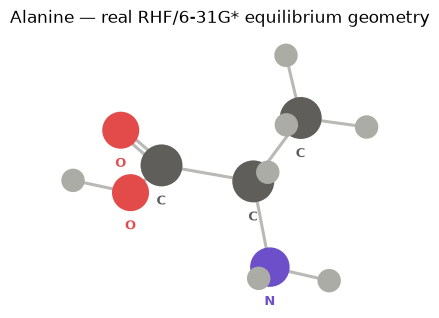

In [2]:
ELEMENT_COLOR = {"C": "#5F5E5A", "N": "#6C4FC9", "O": "#E24B4A", "H": "#ACACA6"}
ELEMENT_RADIUS = {"C": 0.34, "N": 0.32, "O": 0.30, "H": 0.19}   # display units, not physical vdW radii


def project_to_2d(coords_ang):
    centroid = coords_ang.mean(axis=0)
    xc = coords_ang - centroid
    _, _, vt = np.linalg.svd(xc)
    basis = vt[:2]                # (2, 3): the two principal axes
    xy = xc @ basis.T             # (natm, 2)
    return xy, basis


XY, BASIS2D = project_to_2d(COORDS_ANG)


def draw_molecule(ax, xy, bonds=BONDS, symbols=SYMBOLS, alpha=1.0, label_atoms=True,
                   bond_color="#B9B9B5", zorder=1):
    for i, j, order in bonds:
        offsets = [0.0] if order == 1 else [-0.045, 0.045]
        for off in offsets:
            d = xy[j] - xy[i]
            perp = np.array([-d[1], d[0]])
            perp = perp / (np.linalg.norm(perp) + 1e-9) * off
            seg = np.stack([xy[i] + perp, xy[j] + perp])
            ax.plot(seg[:, 0], seg[:, 1], color=bond_color, lw=2.2, alpha=alpha,
                     solid_capstyle="round", zorder=zorder)
    for i, sym in enumerate(symbols):
        ax.add_patch(plt.Circle(xy[i], ELEMENT_RADIUS[sym], color=ELEMENT_COLOR[sym],
                                  alpha=alpha, zorder=zorder + 1, linewidth=0))
        if label_atoms and sym != "H":
            ax.text(xy[i, 0], xy[i, 1] - ELEMENT_RADIUS[sym] - 0.14, sym, ha="center",
                     va="top", fontsize=9, color=ELEMENT_COLOR[sym], alpha=alpha,
                     zorder=zorder + 2, fontweight="bold")


fig, ax = plt.subplots(figsize=(4.5, 4.5))
draw_molecule(ax, XY)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Alanine — real RHF/6-31G* equilibrium geometry")
plt.show()

## 3. UniAug

$$\delta\mathbf{x}_i \sim \mathcal{N}(\mathbf{0},\,\sigma^2 \mathbf{I}_3), i \in S, \qquad \delta\mathbf{x}_i = \mathbf{0}, i \notin S$$

Solid = equilibrium. Ghost = one sampled displaced copy.


moved 3/13 atoms: ['H', 'H', 'H']


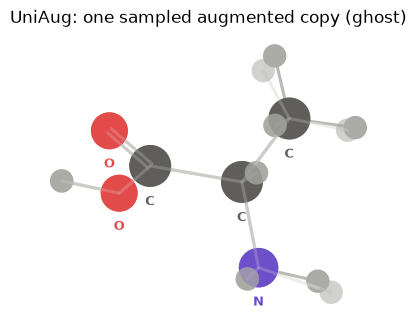

In [3]:
NOISE_SIGMA_ANG = 0.22   # display sigma; real training sigma ~0.004-0.005 A
AUG_ATOM_FRAC = 0.25


def uniaug_sample_3d(rng, frac=AUG_ATOM_FRAC, sigma=NOISE_SIGMA_ANG):
    n_sel = max(1, round(frac * NATM))
    selected = rng.choice(NATM, size=n_sel, replace=False)
    disp = np.zeros((NATM, 3))
    disp[selected] = rng.normal(0.0, sigma, size=(n_sel, 3))
    return disp


rng = np.random.default_rng(7)
disp3d = uniaug_sample_3d(rng)
disp2d = disp3d @ BASIS2D.T
moved = np.linalg.norm(disp3d, axis=1) > 1e-9
print(f"moved {moved.sum()}/{NATM} atoms: {[s for s, m in zip(SYMBOLS, moved) if m]}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
draw_molecule(ax, XY)
draw_molecule(ax, XY + disp2d, alpha=0.55, label_atoms=False, bond_color="#DDDDD9", zorder=3)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("UniAug: one sampled augmented copy (ghost)")
plt.show()

## 4. ModeAug

$$\delta\mathbf{x} = \sum_{k} c_k\,\mathbf{v}_k, \qquad c_k = \sigma\,\varepsilon_k\,w_k, \qquad w_k = \sqrt{n}\,\frac{\lambda_k^{-1/2}}{\lVert \lambda^{-1/2}\rVert_2}$$

All 33 real modes, all atoms, same $\varepsilon_k$ draw shared molecule-wide.


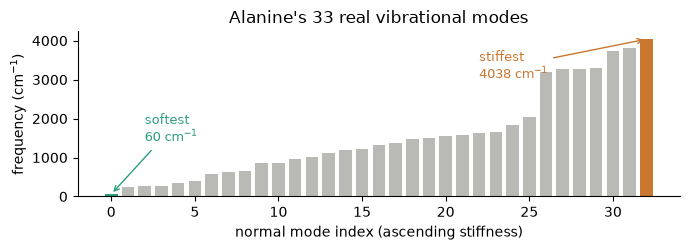

freq ratio stiffest/softest: 67x  ->  weight ratio softest/stiffest: 8x


In [4]:
fig, ax = plt.subplots(figsize=(7, 2.6))
colors = ["#2F9C82" if i == 0 else ("#C9772F" if i == len(FREQ) - 1 else "#B9B9B5")
          for i in range(len(FREQ))]
ax.bar(np.arange(len(FREQ)), FREQ, color=colors, width=0.75)
ax.set_xlabel("normal mode index (ascending stiffness)")
ax.set_ylabel("frequency (cm$^{-1}$)")
ax.set_title("Alanine's 33 real vibrational modes")
ax.annotate(f"softest\n{FREQ[0]:.0f} cm$^{{-1}}$", (0, FREQ[0]), xytext=(2, FREQ.max() * 0.35),
            arrowprops=dict(arrowstyle="->", color="#2F9C82"), color="#2F9C82", fontsize=9)
ax.annotate(f"stiffest\n{FREQ[-1]:.0f} cm$^{{-1}}$", (len(FREQ) - 1, FREQ[-1]),
            xytext=(len(FREQ) - 11, FREQ.max() * 0.75),
            arrowprops=dict(arrowstyle="->", color="#C9772F"), color="#C9772F", fontsize=9)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()

print(f"freq ratio stiffest/softest: {FREQ[-1] / FREQ[0]:.0f}x  ->  "
      f"weight ratio softest/stiffest: {np.sqrt(FREQ[-1] / FREQ[0]):.0f}x")

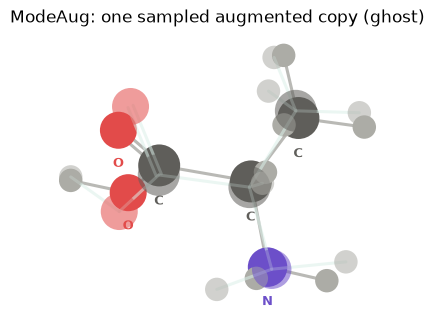

In [5]:
MODE_SIGMA_ANG = 0.5736   # display sigma, calibrated to match UniAug's typical step size


def mode_weights(freq):
    lam = freq.astype(float) ** 2         # eigenvalue of the mass-weighted Hessian is ~freq^2
    inv_sqrt_lam = lam ** -0.5
    n = len(freq)
    return np.sqrt(n) * inv_sqrt_lam / np.linalg.norm(inv_sqrt_lam)


def modeaug_sample_3d(rng, sigma=MODE_SIGMA_ANG, freq=FREQ, modes=NORM_MODE):
    w_k = mode_weights(freq)
    eps_k = rng.normal(0.0, 1.0, size=len(freq))
    c_k = sigma * eps_k * w_k
    return np.einsum("k,kij->ij", c_k, modes)


rng = np.random.default_rng(2155)
disp3d_mode = modeaug_sample_3d(rng)
disp2d_mode = disp3d_mode @ BASIS2D.T

fig, ax = plt.subplots(figsize=(4.5, 4.5))
draw_molecule(ax, XY)
draw_molecule(ax, XY + disp2d_mode, alpha=0.55, label_atoms=False, bond_color="#DBF0E9", zorder=3)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("ModeAug: one sampled augmented copy (ghost)")
plt.show()

## 5. Side by side

Same molecule, same display scale, one sample each.


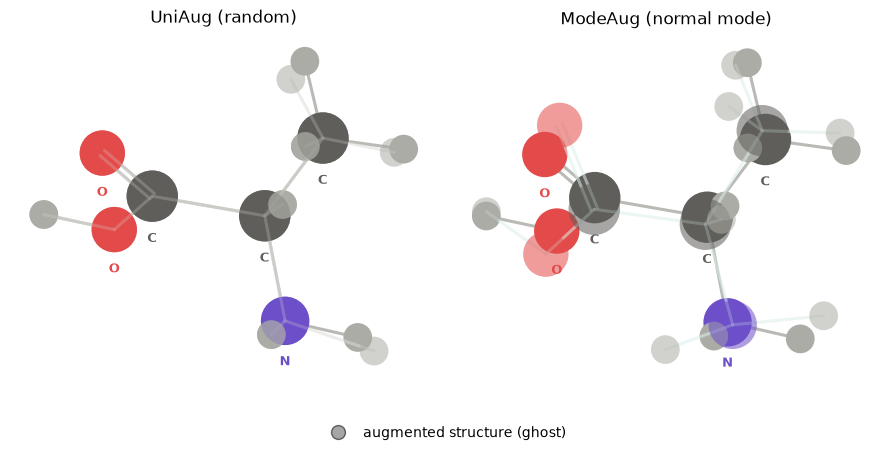

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
rng = np.random.default_rng(7)
disp2d_uni = uniaug_sample_3d(rng) @ BASIS2D.T
rng = np.random.default_rng(2155)
disp2d_mode = modeaug_sample_3d(rng) @ BASIS2D.T

for ax, disp, title, ghost_color in (
    (axes[0], disp2d_uni, "UniAug (random)", "#DDDDD9"),
    (axes[1], disp2d_mode, "ModeAug (normal mode)", "#DBF0E9"),
):
    draw_molecule(ax, XY)
    draw_molecule(ax, XY + disp, alpha=0.55, label_atoms=False, bond_color=ghost_color, zorder=3)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title)

legend_handles = [Line2D([0], [0], marker="o", color="none", markerfacecolor="#5F5E5A",
                          alpha=0.55, markersize=10, label="augmented structure (ghost)")]
fig.legend(handles=legend_handles, loc="lower center", ncol=1, frameon=False, fontsize=10)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

## 6. Relative curvature energy

$$\Delta E \approx \tfrac12\sum_k \lambda_k c_k^2$$

3000 draws/method, matched per-atom step size. Arbitrary units, relative comparison only.


step size (RMS): UniAug=0.370 A, ModeAug=0.443 A
median rel. curvature energy: UniAug=1.7e+06, ModeAug=4.952e+05  (3.4x)


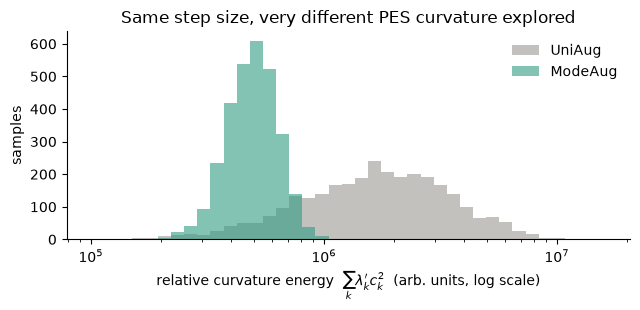

In [7]:
ATOMIC_MASS = {"H": 1.008, "C": 12.011, "N": 14.007, "O": 15.999}
MASS = np.array([ATOMIC_MASS[s] for s in SYMBOLS])   # (natm,) amu


def mode_coeffs(disp3d, modes=NORM_MODE, mass=MASS):
    '''c_k = sum_i m_i * v_k,i . disp_i (mass-metric projection).'''
    return np.einsum("kij,ij->k", modes, disp3d * mass[:, None])


def relative_curvature_energy(disp3d, freq=FREQ):
    lam_rel = freq.astype(float) ** 2      # proportional to lambda_k
    c_k = mode_coeffs(disp3d)
    return 0.5 * np.sum(lam_rel * c_k ** 2)


def typical_atomic_step_ang(disp3d):
    '''RMS per-atom displacement, over atoms that actually moved.'''
    per_atom = np.linalg.norm(disp3d, axis=1)
    active = per_atom > 1e-9
    return np.sqrt(np.mean(per_atom[active] ** 2))


n_samples = 3000
rng = np.random.default_rng(0)
e_uni, step_uni = [], []
e_mode, step_mode = [], []
for _ in range(n_samples):
    d = uniaug_sample_3d(rng)
    e_uni.append(relative_curvature_energy(d)); step_uni.append(typical_atomic_step_ang(d))
    d = modeaug_sample_3d(rng)
    e_mode.append(relative_curvature_energy(d)); step_mode.append(typical_atomic_step_ang(d))
e_uni, e_mode = np.array(e_uni), np.array(e_mode)

print(f"step size (RMS): UniAug={np.mean(step_uni):.3f} A, ModeAug={np.mean(step_mode):.3f} A")
print(f"median rel. curvature energy: UniAug={np.median(e_uni):.4g}, ModeAug={np.median(e_mode):.4g}  "
      f"({np.median(e_uni) / np.median(e_mode):.1f}x)")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
bins = np.logspace(np.log10(min(e_uni.min(), e_mode.min()) + 1e-9),
                    np.log10(max(e_uni.max(), e_mode.max())), 40)
ax.hist(e_uni, bins=bins, alpha=0.6, color="#9A9993", label="UniAug")
ax.hist(e_mode, bins=bins, alpha=0.6, color="#2F9C82", label="ModeAug")
ax.set_xscale("log")
ax.set_xlabel(r"relative curvature energy  $\sum_k \lambda_k' c_k^2$  (arb. units, log scale)")
ax.set_ylabel("samples")
ax.set_title("Same step size, very different PES curvature explored")
ax.legend(frameon=False)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()

## 7. Real DFT check

$$\text{anharm. error} = \big[E_{\text{DFT}}(\mathbf{x}+\delta\mathbf{x}) - E_{\text{DFT}}(\mathbf{x})\big] - \big[-\mathbf{F}^{\top}\delta\mathbf{x} + \tfrac12\delta\mathbf{x}^{\top}\mathbf{H}\delta\mathbf{x}\big]$$

RHF/6-31G* (paper uses wB97X/6-31G*), n=8/group, σ=0.05/0.15 Å. Runs live, ~5 min.


In [8]:
from pyscf import gto, scf, grad

BOHR2ANG = 0.529177210903
HARTREE2EV = 27.211386245988
HARTREE_PER_BOHR_TO_EV_PER_ANG = HARTREE2EV / BOHR2ANG   # ~51.42


def build_mol(coords_ang):
    atom_str = "\n".join(f"{s} {x:.8f} {y:.8f} {z:.8f}" for s, (x, y, z) in zip(SYMBOLS, coords_ang))
    return gto.M(atom=atom_str, basis="6-31g*", unit="Angstrom", verbose=0)


def dft_energy_force(coords_ang):
    '''RHF/6-31G* single point -> (E [Hartree], F [Hartree/Bohr, (natm,3)], converged).'''
    mf = scf.RHF(build_mol(coords_ang))
    e = mf.kernel()
    f = -grad.RHF(mf).kernel()
    return e, f, mf.converged


print("[1/3] reference E/F at equilibrium...")
E0_dft, F0_dft, conv0 = dft_energy_force(COORDS_ANG)
print(f"      E0={E0_dft:.6f} Ha, converged={conv0}, max|F0|={np.abs(F0_dft).max():.2e} Ha/Bohr")

print("[2/3] Cartesian Hessian (~1 min)...")
mf0 = scf.RHF(build_mol(COORDS_ANG))
mf0.kernel()
H_raw = mf0.Hessian().kernel()                                    # (natm, natm, 3, 3)
H = H_raw.transpose(0, 2, 1, 3).reshape(3 * NATM, 3 * NATM)       # (3N, 3N), Hartree/Bohr^2
print("      done.")


def taylor_predict(dx_ang):
    '''dE = -F0.dx + 1/2 dx^T H dx,  dF = -H dx  (atomic units).'''
    dx_bohr = (dx_ang / BOHR2ANG).reshape(-1)
    dE = float(-F0_dft.reshape(-1) @ dx_bohr + 0.5 * dx_bohr @ H @ dx_bohr)
    dF = -(H @ dx_bohr)
    return dE, dF.reshape(NATM, 3)

[1/3] reference E/F at equilibrium...


      E0=-321.861747 Ha, converged=True, max|F0|=3.62e-05 Ha/Bohr
[2/3] Cartesian Hessian (~1 min)...


      done.


In [9]:
import time

SIGMAS_DFT = [0.05, 0.15]
N_SAMPLES = 8

print(f"[3/3] {2 * len(SIGMAS_DFT) * N_SAMPLES} DFT single points...")
rng = np.random.default_rng(123)
records = []
t0 = time.time()
for method, gen in (("UniAug", uniaug_sample_3d), ("ModeAug", modeaug_sample_3d)):
    for sigma in SIGMAS_DFT:
        for i in range(N_SAMPLES):
            dx = gen(rng, sigma=sigma)
            dE_taylor, dF_taylor = taylor_predict(dx)
            E_dft, F_dft, conv = dft_energy_force(COORDS_ANG + dx)
            if not conv:
                print(f"      [warn] SCF did not converge: {method} sigma={sigma} sample={i} -- skipped")
                continue
            dE_dft = E_dft - E0_dft
            dF_dft = F_dft - F0_dft
            records.append(dict(
                method=method, sigma=sigma,
                dE_taylor_eV=dE_taylor * HARTREE2EV,
                dE_dft_eV=dE_dft * HARTREE2EV,
                anharm_err_E_meV=(dE_dft - dE_taylor) * HARTREE2EV * 1000.0,
                rmsF_taylor=np.sqrt(np.mean(np.sum(dF_taylor ** 2, axis=1))) * HARTREE_PER_BOHR_TO_EV_PER_ANG,
                rmsF_dft=np.sqrt(np.mean(np.sum(dF_dft ** 2, axis=1))) * HARTREE_PER_BOHR_TO_EV_PER_ANG,
                rmsF_err=np.sqrt(np.mean(np.sum((dF_dft - dF_taylor) ** 2, axis=1))) * HARTREE_PER_BOHR_TO_EV_PER_ANG,
            ))
    print(f"      ...{method} done ({time.time() - t0:.0f}s elapsed)")

n_ok, n_total = len(records), 2 * len(SIGMAS_DFT) * N_SAMPLES
print(f"finished in {time.time() - t0:.0f}s -- {n_ok}/{n_total} SCF runs converged")

[3/3] 32 DFT single points...


      ...UniAug done (114s elapsed)


      ...ModeAug done (227s elapsed)
finished in 227s -- 32/32 SCF runs converged


In [10]:
header = (f"{'method':8s} {'sigma(A)':>8s} {'n':>3s} | "
          f"{'<dE_dft>':>9s} {'<dE_taylor>':>11s} {'MAE(E)':>9s} | "
          f"{'RMS|dF|_dft':>11s} {'RMS|dF|_tay':>11s} {'RMS_F_err':>10s}")
print(header)
print(f"{'':8s} {'':>8s} {'':>3s} | {'eV':>9s} {'eV':>11s} {'meV':>9s} | "
      f"{'eV/A':>11s} {'eV/A':>11s} {'eV/A':>10s}")
print("-" * len(header))

for method in ("UniAug", "ModeAug"):
    for sigma in SIGMAS_DFT:
        rows = [r for r in records if r["method"] == method and r["sigma"] == sigma]
        if not rows:
            continue
        n = len(rows)
        mE_dft = np.mean([r["dE_dft_eV"] for r in rows])
        mE_tay = np.mean([r["dE_taylor_eV"] for r in rows])
        maeE = np.mean([abs(r["anharm_err_E_meV"]) for r in rows])
        rF_dft = np.mean([r["rmsF_dft"] for r in rows])
        rF_tay = np.mean([r["rmsF_taylor"] for r in rows])
        rF_err = np.mean([r["rmsF_err"] for r in rows])
        print(f"{method:8s} {sigma:8.2f} {n:3d} | "
              f"{mE_dft:9.4f} {mE_tay:11.4f} {maeE:9.2f} | "
              f"{rF_dft:11.4f} {rF_tay:11.4f} {rF_err:10.4f}")

for sigma in SIGMAS_DFT:
    u = np.mean([r["dE_dft_eV"] for r in records if r["method"] == "UniAug" and r["sigma"] == sigma])
    m = np.mean([r["dE_dft_eV"] for r in records if r["method"] == "ModeAug" and r["sigma"] == sigma])
    print(f"sigma={sigma:.2f} A: DFT |dE| UniAug/ModeAug = {u / m:.1f}x  ({u:.3f} vs {m:.3f} eV)")

method   sigma(A)   n |  <dE_dft> <dE_taylor>    MAE(E) | RMS|dF|_dft RMS|dF|_tay  RMS_F_err
                      |        eV          eV       meV |        eV/A        eV/A       eV/A
--------------------------------------------------------------------------------------------
UniAug       0.05   8 |    0.3909      0.3674     26.28 |      2.5994      2.2955     0.4931
UniAug       0.15   8 |    3.3046      3.4660    411.17 |      6.5851      6.6803     3.0571
ModeAug      0.05   8 |    0.0154      0.0154      0.41 |      0.3013      0.3043     0.0360
ModeAug      0.15   8 |    0.1866      0.1380     48.61 |      1.0873      0.8301     0.6456
sigma=0.05 A: DFT |dE| UniAug/ModeAug = 25.4x  (0.391 vs 0.015 eV)
sigma=0.15 A: DFT |dE| UniAug/ModeAug = 17.7x  (3.305 vs 0.187 eV)


## Summary

- UniAug: curvature-agnostic, sparse independent noise
- ModeAug: curvature-aware, coherent mode-weighted motion
- Real DFT: UniAug's $\Delta E$ is 17-25x larger than ModeAug's at matched $\sigma$
- Data: [`alanine_qm_data.npz`](alanine_qm_data.npz) via [`compute_alanine_qm.py`](compute_alanine_qm.py)
